--- 1. Validation Curve (Sweeping Polynomial Degree) ---


/home/saransh/.venv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.461991375105724e-16.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/saransh/.venv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.541262854296071e-16.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/saransh/.venv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.4128982529988548e-16.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/saransh/.venv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.4239210251680057e-16.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/saransh/.venv/li

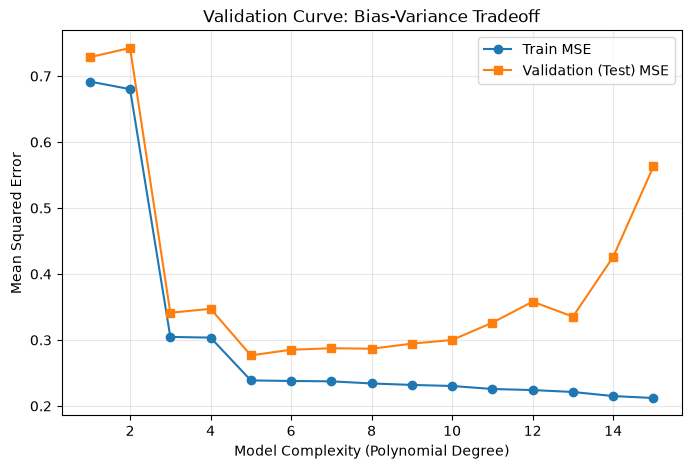


--- 2. Learning Curve (Sweeping Training Set Size) ---


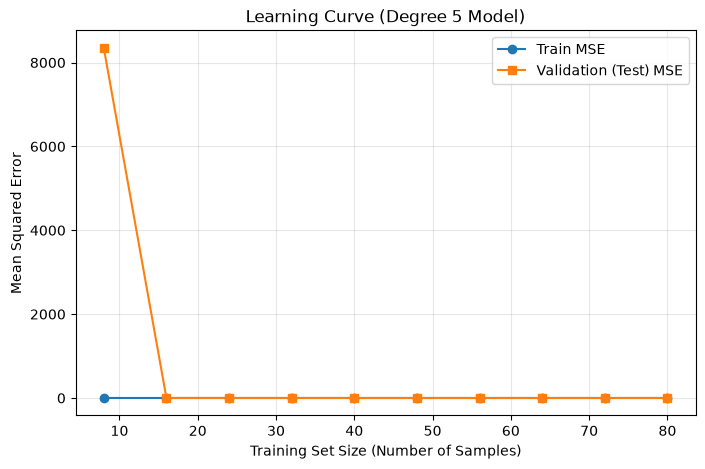


--- 3. Regularization Sweep (Sweeping Ridge Alpha) ---
alpha=  0.001  MSE=0.3001 +/- 0.0863
alpha=  0.010  MSE=0.3000 +/- 0.0866
alpha=  0.100  MSE=0.2997 +/- 0.0898
alpha=  1.000  MSE=0.3032 +/- 0.1037
alpha= 10.000  MSE=0.3626 +/- 0.1252
alpha=100.000  MSE=0.6755 +/- 0.1967


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

# ---------------------------------------------------------
# 1. Setup Data (using your functions from earlier)
# ---------------------------------------------------------
def true_function(x):
    return np.sin(1.5 * x) + 0.5 * x

def generate_data(n_samples=100, noise_std=0.5, x_range=(-3, 3), seed=42):
    rng = np.random.RandomState(seed)
    x = rng.uniform(x_range[0], x_range[1], n_samples)
    y = true_function(x) + rng.normal(0, noise_std, n_samples)
    return x, y

# Generate our dataset. 
# We MUST reshape X to be 2D (n_samples, 1) for sklearn.
x_data, y_data = generate_data(n_samples=100, noise_std=0.5, seed=0)
X = x_data.reshape(-1, 1)
y = y_data

# ---------------------------------------------------------
# 2. Validation Curve: Sweep Model Complexity
# ---------------------------------------------------------
print("--- 1. Validation Curve (Sweeping Polynomial Degree) ---")
degrees = list(range(1, 16))
train_scores_all = []
val_scores_all = []

for d in degrees:
    # Pipeline: expand X to polynomial features, then fit a Ridge model
    pipe = make_pipeline(PolynomialFeatures(d), Ridge(alpha=0.01))
    
    # validation_curve automatically trains and scores for us across 5 folds
    train_scores, val_scores = validation_curve(
        pipe, X, y, param_name="polynomialfeatures__degree",
        param_range=[d], cv=5, scoring="neg_mean_squared_error"
    )
    
    # sklearn returns negative MSE (because it maximizes scores), so we flip the sign
    train_scores_all.append(-train_scores.mean())
    val_scores_all.append(-val_scores.mean())

# Plot the Validation Curve
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_scores_all, 'o-', label='Train MSE')
plt.plot(degrees, val_scores_all, 's-', label='Validation (Test) MSE')
plt.xlabel('Model Complexity (Polynomial Degree)')
plt.ylabel('Mean Squared Error')
plt.title('Validation Curve: Bias-Variance Tradeoff')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ---------------------------------------------------------
# 3. Learning Curve: Sweep Training Set Size
# ---------------------------------------------------------
print("\n--- 2. Learning Curve (Sweeping Training Set Size) ---")
# We use a fixed degree 5 (high variance) model
pipe = make_pipeline(PolynomialFeatures(5), Ridge(alpha=0.01))

# Sweep training set sizes from 10% to 100% of the data
train_sizes, train_scores, val_scores = learning_curve(
    pipe, X, y, train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5, scoring="neg_mean_squared_error"
)

# Flip signs to get positive MSE
train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)

# Plot the Learning Curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mse, 'o-', label='Train MSE')
plt.plot(train_sizes, val_mse, 's-', label='Validation (Test) MSE')
plt.xlabel('Training Set Size (Number of Samples)')
plt.ylabel('Mean Squared Error')
plt.title('Learning Curve (Degree 5 Model)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ---------------------------------------------------------
# 4. Cross-Validation with Regularization Sweep
# ---------------------------------------------------------
print("\n--- 3. Regularization Sweep (Sweeping Ridge Alpha) ---")
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

# Use a high-complexity model (degree 10) that will overfit without regularization
for alpha in alphas:
    pipe = make_pipeline(PolynomialFeatures(10), Ridge(alpha=alpha))
    scores = cross_val_score(pipe, X, y, cv=5, scoring="neg_mean_squared_error")
    # Print mean and standard deviation across the 5 folds
    print(f"alpha={alpha:>7.3f}  MSE={-scores.mean():.4f} +/- {scores.std():.4f}")

Validation Curve: Sweep Model Complexity

In [ ]:
from sklearn.model_selection import validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

degrees = list(range(1, 16))
train_scores_all = []
val_scores_all = []

for d in degrees:
    pipe = make_pipeline(PolynomialFeatures(d), Ridge(alpha=0.01))
    train_scores, val_scores = validation_curve(
        pipe, X, y, param_name="polynomialfeatures__degree",
        param_range=[d], cv=5, scoring="neg_mean_squared_error"
    )
    train_scores_all.append(-train_scores.mean())
    val_scores_all.append(-val_scores.mean())

Learning Curve: Sweep Training Set Size

In [ ]:
from sklearn.model_selection import learning_curve

pipe = make_pipeline(PolynomialFeatures(5), Ridge(alpha=0.01))
train_sizes, train_scores, val_scores = learning_curve(
    pipe, X, y, train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5, scoring="neg_mean_squared_error"
)
train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)

Cross-Validation with Regularization Sweep

In [ ]:
from sklearn.model_selection import cross_val_score

alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
for alpha in alphas:
    pipe = make_pipeline(PolynomialFeatures(10), Ridge(alpha=alpha))
    scores = cross_val_score(pipe, X, y, cv=5, scoring="neg_mean_squared_error")
    print(f"alpha={alpha:>7.3f}  MSE={-scores.mean():.4f} +/- {scores.std():.4f}")